In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    recall_score
)

In [2]:
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR if (CURRENT_DIR / "dataset").exists()
    else CURRENT_DIR.parent
)

DATASET_PATH = PROJECT_ROOT / "dataset"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

IMG_SIZE = (160, 160)
BATCH_SIZE = 16

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "mobilenetv2_finetuned_best.keras"

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

model = tf.keras.models.load_model(MODEL_PATH)

print("Loaded model:", model.name)
print("Parameters:", model.count_params())
print("Model path:", MODEL_PATH)

Loaded model: BrainTumor_MobileNetV2
Parameters: 2263108
Model path: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\mobilenetv2_finetuned_best.keras


In [3]:

test_raw = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

print("Test images:", sum(
    len(labels) for _, labels in test_raw
))
print("Class order:", test_raw.class_names)


Found 246 files belonging to 4 classes.
Test images: 246
Class order: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [4]:

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(
    y_true, y_pred, average="macro"
)
test_macro_recall = recall_score(
    y_true, y_pred, average="macro"
)

print("FINAL TEST RESULTS")
print(f"Accuracy:     {test_accuracy:.4f}")
print(f"Macro F1:     {test_macro_f1:.4f}")
print(f"Macro Recall: {test_macro_recall:.4f}")

print("\nClassification report:")
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)
print(report)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 300ms/step
FINAL TEST RESULTS
Accuracy:     0.8618
Macro F1:     0.8577
Macro Recall: 0.8622

Classification report:
              precision    recall  f1-score   support

      glioma     0.9459    0.8750    0.9091        80
  meningioma     0.8033    0.7778    0.7903        63
    no_tumor     0.8864    0.7959    0.8387        49
   pituitary     0.8060    1.0000    0.8926        54

    accuracy                         0.8618       246
   macro avg     0.8604    0.8622    0.8577       246
weighted avg     0.8668    0.8618    0.8610       246



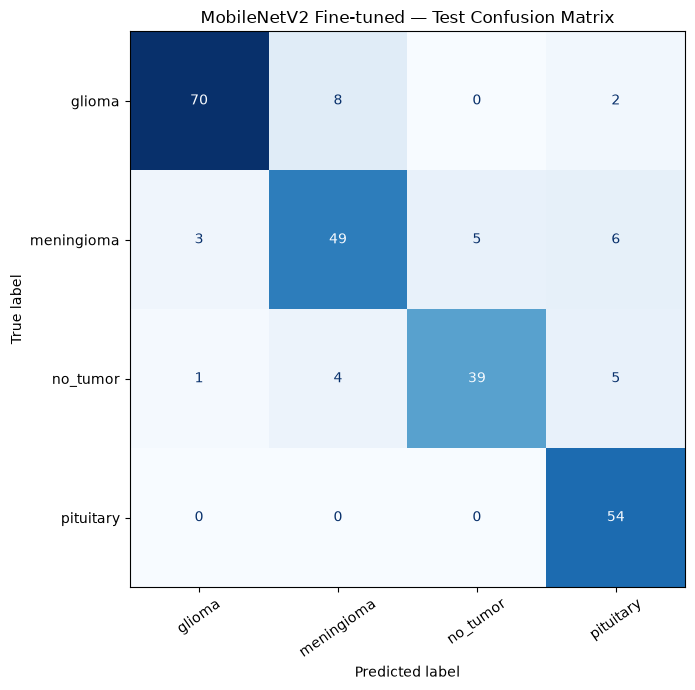

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\final_test_confusion_matrix.png


In [5]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)
plt.xticks(rotation=35)
plt.title("MobileNetV2 Fine-tuned — Test Confusion Matrix")
plt.tight_layout()

cm_path = FIGURES_DIR / "final_test_confusion_matrix.png"
fig.savefig(cm_path, dpi=130, bbox_inches="tight")
plt.show()

print("Saved:", cm_path)


In [6]:

results = {
    "model": "MobileNetV2 Fine-tuned",
    "test_images": int(len(y_true)),
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_macro_recall": float(test_macro_recall),
    "classes": CLASS_NAMES
}

with open(
    REPORTS_DIR / "final_test_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(results, file, indent=2)

print(json.dumps(results, indent=2))
print("Saved: reports/final_test_results.json")


{
  "model": "MobileNetV2 Fine-tuned",
  "test_images": 246,
  "test_accuracy": 0.8617886178861789,
  "test_macro_f1": 0.8576712876566249,
  "test_macro_recall": 0.8621740362811792,
  "classes": [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
  ]
}
Saved: reports/final_test_results.json
